# Machine Learning Problem II: Next-Year EV Sales Share Prediction

## 1. Problem Definition

**Research Question:**

*How accurately can machine learning models predict a country's next-year electric car sales share using historical EV market, adoption, and charging infrastructure indicators?*

### Objective

Bu çalışmada IEA Global EV Outlook 2026 veri setindeki tarihsel göstergeler kullanılarak ülkelerin bir sonraki yıldaki elektrikli otomobil satış paylarının tahmin edilmesi amaçlanmaktadır.

Çalışma bir **Supervised Machine Learning — Regression** problemidir.

### Target Variable (y)

- Next-Year EV Sales Share (%)
- `parameter = EV sales share`
- `mode = Cars`
- `powertrain = EV`

### Candidate Input Features (X)

Veri kapsamı analizinden sonra belirlenecektir. İncelenecek gruplar:

- EV adoption indicators
- EV sales and stock indicators
- Vehicle powertrain indicators (BEV, PHEV, etc.)
- Charging infrastructure indicators
- Electricity demand and battery-related indicators
- Historical growth and lag features

### Planned Algorithms

1. Persistence Baseline
2. Linear Regression
3. Random Forest Regressor
4. Gradient Boosting Regressor

### Evaluation

Modeller tarihsel sırayı koruyan Train–Validation–Test ayrımıyla değerlendirilecektir.

Kullanılacak temel metrikler:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

### Initial Goal

Model eğitiminden önce veri setindeki tüm `parameter`, `mode` ve `powertrain` kombinasyonlarının tarihsel kapsamı analiz edilecektir.

Böylece yeterli ülke-yıl verisine sahip aday özellikler belirlenecek ve gereksiz veri kaybı önlenecektir.

## Veri setini yükleyelim ve genel yapısını inceleyelim

In [1]:

import pandas as pd
from pathlib import Path

# Projenin ana dizinini bul
project_root = next(
    (
        folder for folder in [Path.cwd(), *Path.cwd().parents]
        if (
            folder / "data" / "analysisdataset"
            / "global_ev_cleaned.csv"
        ).exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "global_ev_cleaned.csv bulunamadı."
    )

# Veri setini yükle
data_path = (
    project_root / "data" / "analysisdataset"
    / "global_ev_cleaned.csv"
)

df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)

print("\nColumn Data Types:")
display(df.dtypes.to_frame("dtype"))

print("\nDataset Preview:")
display(df.head())

print("\nCategories:")
display(df["category"].value_counts())

print("\nYear Range:")
print(df["year"].min(), "-", df["year"].max())


Dataset Shape: (48277, 9)

Column Data Types:


,dtype
region_country,str
category,str
parameter,str
mode,str
powertrain,str
year,int64
unit,str
value,float64
Aggregate group,str



Dataset Preview:


,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
0,Chile,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,1.0,Other
1,Norway,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,18.0,Other
2,Portugal,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,6.0,Other
3,Canada,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,2.0,Other
4,Chile,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,4.0,Other



Categories:


category
Historical          47016
Projection-STEPS      640
Projection-CPS        621
Name: count, dtype: int64


Year Range:
2010 - 2035


## Hangi göstergeler tahmin için kullanılabilir?

Önce bütün parameter + mode + powertrain kombinasyonlarını inceleyeceğiz.

Şu sorulara cevap arıyoruz:
1. Kaç farklı gösterge kombinasyonumuz var?
2. Bunlar kaç ülkede bulunuyor?
3. Kaç yıllık tarihsel verileri var?
4. Hangi göstergeler 2025'e kadar uzanıyor?
5. Aynı ülke-yıl-gösterge kombinasyonunda tekrarlanan kayıt var mı?

In [2]:

# Yalnızca tarihsel ve ülke düzeyindeki veriler
historical = df[
    (df["category"] == "Historical") &
    (df["Aggregate group"].isin([
        "Other",
        "Projection_country"
    ]))
].copy()

# Göstergeleri tanımlayan sütunlar
feature_columns = [
    "parameter",
    "mode",
    "powertrain"
]

# Her göstergenin veri kapsamını hesapla
feature_coverage = (
    historical
    .groupby(feature_columns, dropna=False)
    .agg(
        observations=("value", "size"),
        countries=("region_country", "nunique"),
        years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        units=("unit", lambda x: x.dropna().nunique())
    )
    .reset_index()
    .sort_values(
        ["countries", "years"],
        ascending=False
    )
)

print("Historical records:", len(historical))

print(
    "Unique countries:",
    historical["region_country"].nunique()
)

print(
    "Historical year range:",
    historical["year"].min(),
    "-",
    historical["year"].max()
)

print(
    "Total feature combinations:",
    len(feature_coverage)
)

# Aynı ülke-yıl-gösterge için tekrar var mı?
duplicate_count = historical.duplicated(
    ["region_country", "year"] + feature_columns
).sum()

print(
    "Duplicate country-year-feature records:",
    duplicate_count
)

print("\nFeature Coverage:")
display(feature_coverage.head(40))


Historical records: 39779
Unique countries: 62
Historical year range: 2010 - 2025
Total feature combinations: 247
Duplicate country-year-feature records: 0

Feature Coverage:


,parameter,mode,powertrain,observations,countries,years,first_year,last_year,units
16,EV sales,Cars,BEV,760,61,16,2010,2025,1
17,EV sales,Cars,EV,768,61,16,2010,2025,1
30,EV sales share,Cars,EV,762,61,16,2010,2025,1
19,EV sales,Cars,PHEV,659,60,16,2010,2025,1
39,EV stock,Cars,BEV,617,46,16,2010,2025,1
40,EV stock,Cars,EV,620,46,16,2010,2025,1
42,EV stock,Cars,PHEV,544,46,16,2010,2025,1
53,EV stock share,Cars,EV,620,46,16,2010,2025,1
10,EV sales,2 and 3 wheelers,BEV,524,44,16,2010,2025,1
11,EV sales,2 and 3 wheelers,EV,524,44,16,2010,2025,1


Hangi kombinasyonlar, bir sonraki yılın EV satış payını tahmin edebileceğimiz ülke-yıl kayıtlarında bulunuyor?

In [3]:

# Yalnızca tarihsel ve ülke düzeyindeki veriler
historical = df[
    (df["category"] == "Historical") &
    (df["Aggregate group"].isin([
        "Other", "Projection_country"
    ]))
].copy()

# Gelecek yılın EV satış payı hedefi
target = historical[
    (historical["parameter"] == "EV sales share") &
    (historical["mode"] == "Cars") &
    (historical["powertrain"] == "EV")
][["region_country", "year"]].copy()

# Hedef yılı t+1, girdi yılı t
target["year"] = target["year"] - 1

target_keys = target.drop_duplicates()

# Yalnızca sonraki yılın hedefi mevcut olan
# ülke-yıl gözlemlerindeki göstergeleri incele
eligible = historical.merge(
    target_keys,
    on=["region_country", "year"],
    how="inner",
    validate="many_to_one"
)

feature_columns = [
    "parameter", "mode", "powertrain"
]

# Her göstergenin kullanılabilir veri kapsamı
coverage = (
    eligible.groupby(feature_columns, dropna=False)
    .agg(
        records=("value", "size"),
        countries=("region_country", "nunique"),
        years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .reset_index()
    .sort_values(
        ["records", "countries"],
        ascending=False
    )
)

print("Candidate combinations:", len(coverage))
print("Country-year target pairs:", len(target_keys))

print("Duplicate country-year-feature records:",
    eligible.duplicated(
        ["region_country", "year"] + feature_columns
    ).sum()
)

display(coverage.head(40))


Candidate combinations: 247
Country-year target pairs: 762
Duplicate country-year-feature records: 0


,parameter,mode,powertrain,records,countries,years,first_year,last_year
17,EV sales,Cars,EV,698,61,15,2010,2024
30,EV sales share,Cars,EV,695,61,15,2010,2024
16,EV sales,Cars,BEV,690,61,15,2010,2024
19,EV sales,Cars,PHEV,597,60,15,2010,2024
40,EV stock,Cars,EV,564,46,15,2010,2024
53,EV stock share,Cars,EV,564,46,15,2010,2024
39,EV stock,Cars,BEV,561,46,15,2010,2024
42,EV stock,Cars,PHEV,497,46,15,2010,2024
33,EV stock,2 and 3 wheelers,BEV,473,44,15,2010,2024
34,EV stock,2 and 3 wheelers,EV,473,44,15,2010,2024


EV satış verileri en geniş ülke kapsamına sahip. Şarj altyapısı ve fiyat göstergelerinde ise veri kapsamı giderek daralıyor.

Örneğin:
- EV Sales Share kullanırsak 61 ülkeye ait kayıtlarımız var.
- EV Stock eklersek ortak gözlemlerin ülke kapsamı en fazla 46 olabilir.
- Ultra-fast şarj sayısını zorunlu tutarsak ülke kapsamı en fazla 33'e düşebilir.
Bu nedenle bütün özellikleri zorunlu tutmak çok fazla veri kaybetmemize neden olabilir.

## Ortak veri kapsamını inceleyelim 

EV satış, stok ve şarj altyapısı özelliklerini birlikte kullandığımızda kaç ülke ve kaç eğitim gözlemimiz kalıyor?

In [4]:

# İnceleyeceğimiz aday özellik kombinasyonları
candidate_map = {
    ("EV sales share", "Cars", "EV"): "ev_sales_share",
    ("EV sales", "Cars", "EV"): "ev_sales",
    ("EV sales", "Cars", "BEV"): "bev_sales",
    ("EV sales", "Cars", "PHEV"): "phev_sales",
    ("EV stock", "Cars", "EV"): "ev_stock",
    ("EV stock share", "Cars", "EV"): "ev_stock_share",
    ("EV charging points", "EVSE",
     "Publicly available slow"): "public_slow",
    ("EV charging points", "EVSE",
     "Publicly available fast"): "public_fast"
}

# Üçlü kombinasyondan özellik ismi oluştur
candidate_data_long = eligible.copy()

candidate_data_long["feature"] = [
    candidate_map.get((p, m, t))
    for p, m, t in zip(
        candidate_data_long["parameter"],
        candidate_data_long["mode"],
        candidate_data_long["powertrain"]
    )
]

# Seçilmeyen kombinasyonları çıkar
candidate_data_long = candidate_data_long.dropna(
    subset=["feature"]
)

# Ülke-yıl bazında özellik tablosu
regression_wide = candidate_data_long.pivot(
    index=["region_country", "year"],
    columns="feature",
    values="value"
)

feature_sets = {
    "A - Market": [
        "ev_sales_share", "ev_sales",
        "bev_sales", "phev_sales"
    ],
    "B - Market & Stock": [
        "ev_sales_share", "ev_sales",
        "bev_sales", "phev_sales",
        "ev_stock", "ev_stock_share"
    ],
    "C - Market & Infrastructure": [
        "ev_sales_share", "ev_sales",
        "bev_sales", "phev_sales",
        "ev_stock", "ev_stock_share",
        "public_slow", "public_fast"
    ]
}

coverage_results = []

for name, features in feature_sets.items():

    complete = regression_wide[features].dropna()

    coverage_results.append({
        "Feature Set": name,
        "Features": len(features),
        "Complete Country-Year Rows": len(complete),
        "Countries": complete.index.get_level_values(
            "region_country"
        ).nunique(),
        "Years": complete.index.get_level_values(
            "year"
        ).nunique()
    })

display(pd.DataFrame(coverage_results))


,Feature Set,Features,Complete Country-Year Rows,Countries,Years
0,A - Market,4,587,60,15
1,B - Market & Stock,6,488,46,15
2,C - Market & Infrastructure,8,347,41,14


In [5]:

# Üç özellik setinin yıllara göre veri kapsamı

temporal_results = []

for name, features in feature_sets.items():

    complete = regression_wide[features].dropna().reset_index()

    for year, group in complete.groupby("year"):

        temporal_results.append({
            "Feature Set": name,
            "Input Year": int(year),
            "Target Year": int(year) + 1,
            "Observations": len(group),
            "Countries": group["region_country"].nunique()
        })

temporal_coverage = pd.DataFrame(temporal_results)

# Girdi yılına göre karşılaştırma
year_comparison = temporal_coverage.pivot(
    index="Target Year",
    columns="Feature Set",
    values="Observations"
).fillna(0).astype(int)

print("Available observations by target year:")
display(year_comparison)

# Örnek Train / Validation / Test ayrımı
print("\nPotential Temporal Split:")

def assign_split(target_year):
    if target_year <= 2022:
        return "Train"
    elif target_year <= 2024:
        return "Validation"
    else:
        return "Test"

temporal_coverage["Split"] = (
    temporal_coverage["Target Year"].apply(assign_split)
)

split_summary = temporal_coverage.pivot_table(
    index="Feature Set",
    columns="Split",
    values="Observations",
    aggfunc="sum",
    fill_value=0
)

display(
    split_summary.reindex(
        columns=["Train", "Validation", "Test"],
        fill_value=0
    )
)


Available observations by target year:


Feature Set,A - Market,B - Market & Stock,C - Market & Infrastructure
Target Year,,,
2011,5,4,0
2012,14,14,1
2013,22,20,7
2014,25,23,13
2015,26,25,16
2016,37,34,18
2017,39,34,21
2018,44,38,25
2019,45,38,28



Potential Temporal Split:


Split,Train,Validation,Test
Feature Set,,,
A - Market,415,113,59
B - Market & Stock,355,87,46
C - Market & Infrastructure,228,78,41


In [6]:

# Aday özelliklerin eksik veri analizi

candidate_features = [
    "ev_sales_share",
    "ev_sales",
    "bev_sales",
    "phev_sales",
    "ev_stock",
    "ev_stock_share",
    "public_slow",
    "public_fast"
]

# Hedefi mevcut olan ülke-yıl kayıtlarını seç
X_candidates = regression_wide.reindex(
    columns=candidate_features
)

# Her özelliğin veri kapsamı
missing_analysis = pd.DataFrame({
    "Available": X_candidates.notna().sum(),
    "Missing": X_candidates.isna().sum(),
    "Missing (%)": X_candidates.isna().mean() * 100
})

display(
    missing_analysis.sort_values(
        "Missing (%)"
    ).round(2)
)

print(
    "Total available country-year rows:",
    len(X_candidates)
)


,Available,Missing,Missing (%)
feature,,,
ev_sales,698,7,0.99
ev_sales_share,695,10,1.42
bev_sales,690,15,2.13
phev_sales,597,108,15.32
ev_stock,564,141,20.00
ev_stock_share,564,141,20.00
public_slow,393,312,44.26
public_fast,362,343,48.65


Total available country-year rows: 705


In [7]:

# Hedef yılına göre eksik veri oranları

year_missing = (
    X_candidates.isna()
    .groupby(
        X_candidates.index.get_level_values("year") + 1
    )
    .mean()
    .mul(100)
    .round(2)
)

year_missing.index.name = "target_year"

print("Missing Percentage by Target Year:")
display(year_missing)

# Farklı özellik setleriyle kaç gözlem korunabilir?
feature_options = {
    "Sales Share Only": [
        "ev_sales_share"
    ],
    "Core Market": [
        "ev_sales_share",
        "ev_sales",
        "bev_sales"
    ],
    "Market + PHEV": [
        "ev_sales_share",
        "ev_sales",
        "bev_sales",
        "phev_sales"
    ],
    "Market + Stock": [
        "ev_sales_share",
        "ev_sales",
        "bev_sales",
        "phev_sales",
        "ev_stock",
        "ev_stock_share"
    ],
    "Market + Infrastructure": candidate_features
}

results = []

for name, features in feature_options.items():

    complete = X_candidates[features].dropna()

    results.append({
        "Feature Set": name,
        "Features": len(features),
        "Available Rows": len(complete),
        "Countries": complete.index.get_level_values(
            "region_country"
        ).nunique(),
        "Lost Rows": len(X_candidates) - len(complete)
    })

display(pd.DataFrame(results))


Missing Percentage by Target Year:


feature,ev_sales_share,ev_sales,bev_sales,phev_sales,ev_stock,ev_stock_share,public_slow,public_fast
target_year,,,,,,,,
2011,13.64,13.64,13.64,77.27,9.09,9.09,86.36,95.45
2012,3.33,3.33,3.33,53.33,13.33,13.33,76.67,86.67
2013,3.03,3.03,3.03,33.33,9.09,9.09,57.58,66.67
2014,0.00,0.00,2.86,25.71,5.71,5.71,51.43,54.29
2015,2.78,2.78,5.56,25.00,2.78,2.78,41.67,50.00
2016,0.00,0.00,2.13,19.15,21.28,21.28,53.19,61.70
2017,0.00,0.00,2.08,16.67,22.92,22.92,52.08,56.25
2018,0.00,0.00,3.92,9.80,21.57,21.57,47.06,49.02
2019,1.92,0.00,3.85,9.62,23.08,23.08,42.31,44.23


,Feature Set,Features,Available Rows,Countries,Lost Rows
0,Sales Share Only,1,695,61,10
1,Core Market,3,687,61,18
2,Market + PHEV,4,587,60,118
3,Market + Stock,6,488,46,217
4,Market + Infrastructure,8,347,41,358


In [8]:

import numpy as np
import pandas as pd

# Üç satış göstergesini birlikte incele
sales_check = regression_wide[
    ["ev_sales", "bev_sales", "phev_sales"]
].copy()

# Üç değerin de mevcut olduğu gözlemler
complete_sales = sales_check.dropna().copy()

# EV toplamıyla BEV + PHEV toplamını karşılaştır
complete_sales["bev_plus_phev"] = (
    complete_sales["bev_sales"] +
    complete_sales["phev_sales"]
)

complete_sales["difference"] = (
    complete_sales["ev_sales"] -
    complete_sales["bev_plus_phev"]
)

complete_sales["relative_difference_pct"] = (
    complete_sales["difference"].abs()
    / complete_sales["ev_sales"].replace(0, np.nan)
    * 100
)

print("Complete Sales Records:", len(complete_sales))

print("\nDifference Statistics:")
display(
    complete_sales[
        ["difference", "relative_difference_pct"]
    ].describe()
)

# Yaklaşık eşitliği kontrol et
close_match = np.isclose(
    complete_sales["ev_sales"],
    complete_sales["bev_plus_phev"],
    rtol=0.01,
    atol=1
)

print("\nMatching Records:", close_match.sum())

print(
    "Match Percentage:",
    round(close_match.mean() * 100, 2)
)

# PHEV eksik ama EV ve BEV mevcut olan kayıtlar
recoverable = sales_check[
    sales_check["phev_sales"].isna() &
    sales_check["ev_sales"].notna() &
    sales_check["bev_sales"].notna()
].copy()

recoverable["estimated_phev"] = (
    recoverable["ev_sales"] -
    recoverable["bev_sales"]
)

print("\nPotentially Recoverable PHEV Records:",
      len(recoverable))

print("Negative Derived Values:",
      (recoverable["estimated_phev"] < 0).sum())

display(recoverable.head(10))


Complete Sales Records: 589

Difference Statistics:


feature,difference,relative_difference_pct
count,589.000000,589.000000
mean,-369.354839,1.066636
std,13878.955585,1.299284
min,-300000.000000,0.000000
25%,-2.000000,0.000000
50%,0.000000,0.512821
75%,9.000000,1.818182
max,80000.000000,6.428571



Matching Records: 364
Match Percentage: 61.8

Potentially Recoverable PHEV Records: 101
Negative Derived Values: 0


feature              ev_sales  bev_sales  phev_sales  estimated_phev
region_country year                                                 
Australia      2011      49.0       49.0         NaN             0.0
Austria        2013     650.0      650.0         NaN             0.0
               2014    1700.0     1700.0         NaN             0.0
Brazil         2010      10.0       10.0         NaN             0.0
               2011       8.0        8.0         NaN             0.0
               2014      61.0       61.0         NaN             0.0
Bulgaria       2015      21.0       21.0         NaN             0.0
Cambodia       2021      42.0       42.0         NaN             0.0
               2022     290.0      290.0         NaN             0.0
               2023     500.0      500.0         NaN             0.0

In [10]:

# 2035 EV satış payı projeksiyonu bulunan ülkeler
projection_2035 = df[
    (df["category"].isin([
        "Projection-STEPS",
        "Projection-CPS"
    ])) &
    (df["year"] == 2035) &
    (df["parameter"] == "EV sales share") &
    (df["mode"] == "Cars") &
    (df["powertrain"] == "EV")
].copy()

selected_countries = sorted(
    projection_2035["region_country"]
    .dropna()
    .unique()
)

print("2035 projeksiyonu bulunan ülke/bölge sayısı:",
      len(selected_countries))

print("\nÜlkeler / Bölgeler:")
print(selected_countries)

# Bu ülkelerin tarihsel verilerindeki gösterge kapsamı
selected_historical = historical[
    historical["region_country"].isin(
        selected_countries
    )
].copy()

coverage = (
    selected_historical
    .groupby(["parameter", "mode", "powertrain"])
    .agg(
        observation_count=("value", "count"),
        country_count=("region_country", "nunique"),
        year_count=("year", "nunique")
    )
    .sort_values(
        "observation_count",
        ascending=False
    )
)

print("\nEn fazla veri bulunan 25 gösterge:")
display(coverage.head(25))


2035 projeksiyonu bulunan ülke/bölge sayısı: 9

Ülkeler / Bölgeler:
['China', 'Europe', 'India', 'Japan', 'Korea', 'Latin America', 'Southeast Asia', 'USA', 'World']

En fazla veri bulunan 25 gösterge:


,,,observation_count,country_count,year_count
parameter,mode,powertrain,,,
EV stock,Cars,EV,80,5,16
EV sales,Cars,BEV,80,5,16
EV stock share,Cars,EV,80,5,16
EV stock,Cars,BEV,80,5,16
EV sales share,Cars,EV,80,5,16
EV sales,Cars,EV,80,5,16
Electricity demand,Cars,EV,74,5,16
"Oil displacement, Mbd",Vans,EV,68,5,16
Oil displacement Mlge,Vans,EV,68,5,16


## Adım 1 — Regression veri setimizi oluşturalım

## 3. Regresyon Veri Setinin Hazırlanması

### Amaç

Bu aşamada, bir ülkenin mevcut yıldaki elektrikli otomobil pazarı göstergelerini kullanarak **bir sonraki yılın elektrikli otomobil satış payını tahmin etmek** için ülke-yıl bazında bir veri seti hazırlanacaktır.

### Girdi Özellikleri (X)

Modelde üç sayısal özellik kullanılacaktır:

- `ev_sales_share`: Mevcut yıldaki elektrikli otomobil satış payı (%)
- `ev_sales`: Mevcut yıldaki toplam elektrikli otomobil satış sayısı
- `bev_sales`: Mevcut yıldaki tamamen bataryalı elektrikli otomobil (BEV) satış sayısı

### Hedef Değişken (y)

- `target_next_year_share`: Bir sonraki yılın elektrikli otomobil satış payı (%)

### Veri Hazırlama Yöntemi

Yalnızca **Historical (tarihsel)** kategorisindeki kayıtlar kullanılacaktır.

Her ülkenin `t` yılındaki girdi özellikleri, aynı ülkenin `t+1` yılındaki gerçek EV satış payıyla eşleştirilecektir.

Örneğin Türkiye'nin 2024 yılına ait satış göstergeleri kullanılarak 2025 yılındaki EV satış payı tahmin edilecektir.

### Özellik Seçiminin Gerekçesi

Önceki veri uygunluk analizinde, seçilen üç özelliğin birlikte eksiksiz bulunduğu **687 ülke-yıl gözlemi** tespit edilmiştir.

Bu özellikler, diğer aday göstergelere kıyasla daha geniş tarihsel veri kapsamına sahip oldukları ve elektrikli otomobil pazarının mevcut durumunu temsil ettikleri için başlangıç modeli kapsamında seçilmiştir.

### Sonraki Aşama

Hazırlanan veri seti, zaman sıralaması korunarak **Eğitim (Train), Doğrulama (Validation) ve Test (Test)** kümelerine ayrılacaktır.

Bu ayrım sayesinde gelecekteki hedef değerlerin modelin eğitim sürecine sızması (*Data Leakage*) önlenecektir.

Ardından regresyon algoritmaları eğitilecek ve tahmin başarıları gerçek tarihsel değerlerle karşılaştırılarak değerlendirilecektir.

In [ ]:
# Adım 1 - Regression Dataset Preparation

core_features = [
    "ev_sales_share",
    "ev_sales",
    "bev_sales"
]

# 1. Mevcut yılın model girdileri
X_data = (
    regression_wide[core_features]
    .dropna()
    .reset_index()
)

# 2. Bir sonraki yılın gerçek EV satış payı
target_data = historical[
    (historical["parameter"] == "EV sales share") &
    (historical["mode"] == "Cars") &
    (historical["powertrain"] == "EV")
][["region_country", "year", "value"]].copy()

target_data = target_data.rename(
    columns={"value": "target_next_year_share"}
)

# Hedefi t+1 yılından t yılına eşleştir
target_data["year"] = target_data["year"] - 1

# Ülke-yıl tekrarlarını kontrol et
assert not target_data.duplicated(
    ["region_country", "year"]
).any(), "Duplicate target records found!"

# 3. Girdilerle hedefi birleştir
regression_core = X_data.merge(
    target_data,
    on=["region_country", "year"],
    how="inner",
    validate="one_to_one"
)

# Eksik hedefleri çıkar
regression_core = regression_core.dropna(
    subset=["target_next_year_share"]
)

# 4. Tahmin edilecek yılı ekle
regression_core["target_year"] = (
    regression_core["year"] + 1
)

# 5. Sonuçları kontrol et
print("Dataset Shape:", regression_core.shape)
print(
    "Unique Countries:",
    regression_core["region_country"].nunique()
)

print(
    "Missing Values:",
    regression_core.isna().sum().sum()
)

print(
    "Invalid Target Values:",
    (~regression_core["target_next_year_share"]
       .between(0, 100)).sum()
)

print("\nDataset Preview:")
display(regression_core.head(10))

print("\nTarget Year Distribution:")
display(
    regression_core["target_year"]
    .value_counts()
    .sort_index()
)


Dataset Shape: (687, 7)
Unique Countries: 61
Missing Values: 0
Invalid Target Values: 0

Dataset Preview:


,region_country,year,ev_sales_share,ev_sales,bev_sales,target_next_year_share,target_year
0,Australia,2011,0.0061,49.0,49.0,0.029,2012
1,Australia,2012,0.0290,250.0,170.0,0.033,2013
2,Australia,2013,0.0330,290.0,190.0,0.150,2014
3,Australia,2014,0.1500,1300.0,370.0,0.190,2015
4,Australia,2015,0.1900,1800.0,760.0,0.150,2016
5,Australia,2016,0.1500,1400.0,670.0,0.250,2017
6,Australia,2017,0.2500,2300.0,1200.0,0.420,2018
7,Australia,2018,0.4200,3600.0,1800.0,1.200,2019
8,Australia,2019,1.2000,9200.0,6300.0,0.980,2020
9,Australia,2020,0.9800,6900.0,5200.0,2.700,2021



Target Year Distribution:


target_year
2011    19
2012    29
2013    32
2014    34
2015    34
2016    46
2017    47
2018    49
2019    49
2020    54
2021    55
2022    59
2023    60
2024    60
2025    60
Name: count, dtype: int64

## Adım 2 — Train, Validation ve Test ayrımı

In [12]:

# Adım 2: Veriyi kronolojik olarak ayırma

train_df = regression_core[
    regression_core["target_year"] <= 2022
].copy()

val_df = regression_core[
    regression_core["target_year"].between(2023, 2024)
].copy()

test_df = regression_core[
    regression_core["target_year"] == 2025
].copy()

features = [
    "ev_sales_share",
    "ev_sales",
    "bev_sales"
]

target = "target_next_year_share"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nToplam gözlem:",
      len(train_df) + len(val_df) + len(test_df))


Train: (507, 3) (507,)
Validation: (120, 3) (120,)
Test: (60, 3) (60,)

Toplam gözlem: 687


## Adım 3 — Baseline Model
ML algoritmalarını eğitmeden önce çok basit bir tahmin yöntemi oluşturacağız: Persistence Baseline.

Bu yöntem, bir ülkenin gelecek yılki EV satış payının mevcut yıl ile aynı kalacağını varsayar.

Örneğin:
- 2023 EV satış payı: %10
- Baseline'ın 2024 tahmini: %10
- Gerçek 2024 EV satış payı: %15
- Tahmin hatası: 5 yüzde puan
Bu model hiçbir şey öğrenmez. Amacımız, daha sonra eğiteceğimiz Linear Regression ve Random Forest modellerinin bu basit yöntemden daha başarılı olup olmadığını görmek

In [13]:

# Adım 3: Persistence Baseline

import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Gelecek yılın satış payını mevcut yıla eşit kabul et
y_val_baseline = X_val["ev_sales_share"]

# Değerlendirme metrikleri
baseline_mae = mean_absolute_error(y_val, y_val_baseline)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_baseline)
)

baseline_r2 = r2_score(y_val, y_val_baseline)

print("Persistence Baseline - Validation Results")
print(f"MAE:  {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²:   {baseline_r2:.4f}")


Persistence Baseline - Validation Results
MAE:  4.0616
RMSE: 6.4966
R²:   0.8838


## Adım 4 — Linear Regression modelini eğitelim
Bu aşamada model üç özelliğimiz arasındaki ilişkileri öğrenerek bir sonraki yılın EV satış payını tahmin edecek.

Özelliklerimizin ölçekleri farklı olduğu için StandardScaler kullanacağız. Bu işlem yalnızca eğitim verisinden öğrenilecek.

In [14]:

# Adım 4: Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Modeli oluştur
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

# Yalnızca eğitim verisiyle eğit
linear_model.fit(X_train, y_train)

# Validation tahminleri
y_val_linear = linear_model.predict(X_val)

# Değerlendirme
linear_mae = mean_absolute_error(y_val, y_val_linear)
linear_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_linear)
)
linear_r2 = r2_score(y_val, y_val_linear)

print("Linear Regression - Validation Results")
print(f"MAE:  {linear_mae:.4f}")
print(f"RMSE: {linear_rmse:.4f}")
print(f"R²:   {linear_r2:.4f}")

print("\nBaseline ile karşılaştırma:")
print(f"Baseline MAE: {baseline_mae:.4f}")
print(f"Linear MAE:   {linear_mae:.4f}")


Linear Regression - Validation Results
MAE:  4.3887
RMSE: 7.5434
R²:   0.8433

Baseline ile karşılaştırma:
Baseline MAE: 4.0616
Linear MAE:   4.3887


## Adım 5 — Random Forest Regression
Şimdi ikinci ML algoritmamızı deneyelim.

Linear Regression doğrusal ilişkileri öğrenirken Random Forest, değişkenler arasındaki doğrusal olmayan ilişkileri de modelleyebilir.

Aynı 507 eğitim gözlemini kullanacağız ve 120 doğrulama gözlemi üzerinde değerlendireceğiz.

In [15]:

# Adım 5: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

# Modeli oluştur
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Eğitim
rf_model.fit(X_train, y_train)

# Validation tahminleri
y_val_rf = rf_model.predict(X_val)

# Değerlendirme
rf_mae = mean_absolute_error(y_val, y_val_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_rf)
)

rf_r2 = r2_score(y_val, y_val_rf)

print("Random Forest - Validation Results")
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")

# Üç yöntemi karşılaştır
comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2,
        rf_r2
    ]
})

display(comparison.sort_values("MAE"))


Random Forest - Validation Results
MAE:  5.1560
RMSE: 7.6547
R²:   0.8387


,Model,MAE,RMSE,R2
0,Persistence Baseline,4.061583,6.496620,0.883780
1,Linear Regression,4.388684,7.543401,0.843311
2,Random Forest,5.155992,7.654668,0.838654


In [17]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 7.2 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [18]:

# Adım 6: XGBoost Regression

from xgboost import XGBRegressor

# Modeli oluştur
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Yalnızca Train verisiyle eğit
xgb_model.fit(X_train, y_train)

# Validation tahminleri
y_val_xgb = xgb_model.predict(X_val)

# Değerlendirme
xgb_mae = mean_absolute_error(y_val, y_val_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_val, y_val_xgb))
xgb_r2 = r2_score(y_val, y_val_xgb)

# Önceki modellerle karşılaştır
comparison_xgb = pd.concat([
    comparison,
    pd.DataFrame([{
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "R2": xgb_r2
    }])
], ignore_index=True)

print("2023–2024 Validation Sonuçları")

display(
    comparison_xgb.sort_values("MAE").round(4)
)


2023–2024 Validation Sonuçları


,Model,MAE,RMSE,R2
0,Persistence Baseline,4.0616,6.4966,0.8838
1,Linear Regression,4.3887,7.5434,0.8433
3,XGBoost,4.5128,6.9071,0.8686
2,Random Forest,5.1560,7.6547,0.8387


In [19]:

# Adım 7: 2025 Test Değerlendirmesi

from sklearn.base import clone

# 1. Train ve Validation verilerini birleştir
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

# 2. Modelleri yeniden oluştur ve eğit
linear_final = clone(linear_model)
rf_final = clone(rf_model)
xgb_final = clone(xgb_model)

linear_final.fit(X_train_final, y_train_final)
rf_final.fit(X_train_final, y_train_final)
xgb_final.fit(X_train_final, y_train_final)

# 3. 2025 tahminlerini oluştur
test_predictions = {
    "Persistence Baseline": X_test["ev_sales_share"],
    "Linear Regression": linear_final.predict(X_test),
    "Random Forest": rf_final.predict(X_test),
    "XGBoost": xgb_final.predict(X_test)
}

# 4. Performans metriklerini hesapla
test_results = []

for model_name, predictions in test_predictions.items():
    test_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

test_comparison = pd.DataFrame(test_results)

# 5. Sonuçları göster
print("2025 Test Sonuçları")
print("Eğitim gözlemi:", len(X_train_final))
print("Test gözlemi:", len(X_test))

display(
    test_comparison.sort_values("MAE").round(4)
)


2025 Test Sonuçları
Eğitim gözlemi: 627
Test gözlemi: 60


,Model,MAE,RMSE,R2
1,Linear Regression,4.1144,5.7010,0.9211
3,XGBoost,4.2223,5.7283,0.9203
2,Random Forest,4.3194,5.8551,0.9168
0,Persistence Baseline,5.5207,7.1588,0.8756


In [20]:

# Adım 8: Ülke bazında 2025 tahminleri

country_results = test_df[
    ["region_country", "ev_sales_share",
     "target_next_year_share"]
].reset_index(drop=True).copy()

country_results = country_results.rename(columns={
    "ev_sales_share": "2024 Gerçek",
    "target_next_year_share": "2025 Gerçek"
})

# Model tahminlerini ekle
for model_name, predictions in test_predictions.items():
    country_results[model_name] = np.asarray(predictions)

# Linear Regression tahmin hatası
country_results["Linear Mutlak Hata"] = (
    country_results["2025 Gerçek"] -
    country_results["Linear Regression"]
).abs()

# Beş ülkeyi karşılaştır
five_countries = [
    "China", "India", "Japan", "Korea", "USA"
]

display(
    country_results[
        country_results["region_country"].isin(five_countries)
    ].round(2)
)


,region_country,2024 Gerçek,2025 Gerçek,Persistence Baseline,Linear Regression,Random Forest,XGBoost,Linear Mutlak Hata
8,China,48.0,53.0,48.0,53.18,56.71,54.330002,0.18
22,India,2.1,4.0,2.1,3.75,2.74,2.900000,0.25
27,Japan,2.8,3.0,2.8,4.27,5.95,6.100000,1.27
29,Korea,7.4,11.0,7.4,9.57,10.14,8.840000,1.43
54,USA,10.0,10.0,10.0,13.82,14.11,14.610000,3.82


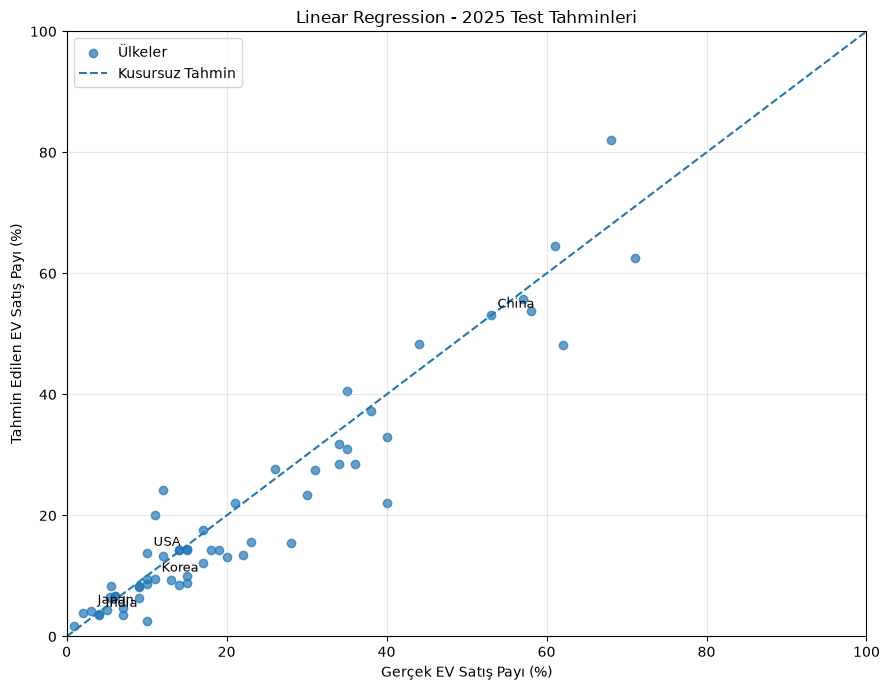

In [21]:

# Adım 9: Gerçek ve Tahmin Edilen EV Satış Payları

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

# Tüm ülkelerin gerçek ve tahmin edilen değerleri
plt.scatter(
    country_results["2025 Gerçek"],
    country_results["Linear Regression"],
    alpha=0.7,
    label="Ülkeler"
)

# Kusursuz tahmin çizgisi
plt.plot(
    [0, 100], [0, 100],
    linestyle="--",
    label="Kusursuz Tahmin"
)

# Seçilen 5 ülkeyi işaretle
selected = country_results[
    country_results["region_country"].isin(five_countries)
]

for _, row in selected.iterrows():
    plt.annotate(
        row["region_country"],
        (
            row["2025 Gerçek"],
            row["Linear Regression"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Gerçek EV Satış Payı (%)")
plt.ylabel("Tahmin Edilen EV Satış Payı (%)")
plt.title("Linear Regression - 2025 Test Tahminleri")

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

# Adım 9: Overfitting Kontrolü

models = {
    "Linear Regression": linear_final,
    "Random Forest": rf_final,
    "XGBoost": xgb_final
}

overfitting_results = []

for name, model in models.items():

    # Eğitim verisindeki tahminler
    train_pred = model.predict(X_train_final)

    # Test verisindeki tahminler
    test_pred = model.predict(X_test)

    train_mae = mean_absolute_error(
        y_train_final, train_pred
    )

    test_mae = mean_absolute_error(
        y_test, test_pred
    )

    overfitting_results.append({
        "Model": name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Fark": test_mae - train_mae
    })

display(
    pd.DataFrame(overfitting_results).round(4)
)


,Model,Train MAE,Test MAE,Fark
0,Linear Regression,2.0539,4.1144,2.0605
1,Random Forest,1.3707,4.3194,2.9487
2,XGBoost,1.0674,4.2223,3.1549


In [23]:

# Adım 10: En yüksek tahmin hatasına sahip 10 ülke

largest_errors = country_results.sort_values(
    "Linear Mutlak Hata",
    ascending=False
).head(10)

display(
    largest_errors[
        [
            "region_country",
            "2024 Gerçek",
            "2025 Gerçek",
            "Linear Regression",
            "Linear Mutlak Hata"
        ]
    ].round(2)
)


,region_country,2024 Gerçek,2025 Gerçek,Linear Regression,Linear Mutlak Hata
59,Viet Nam,19.0,40.0,22.14,17.86
36,Nepal,74.0,68.0,82.05,14.05
21,Iceland,43.0,62.0,48.17,13.83
57,Uruguay,13.0,28.0,15.41,12.59
28,Jordan,21.0,12.0,24.15,12.15
6,Canada,17.0,11.0,20.05,9.05
53,Turkiye,11.0,22.0,13.42,8.58
14,Denmark,56.0,71.0,62.58,8.42
30,Lao PDR,25.0,36.0,28.51,7.49
52,Thailand,13.0,23.0,15.56,7.44


In [24]:

# Adım 11: Regression sonuçlarını kaydetme

# Her ülke için dört yöntemin mutlak hatasını ekle
for model_name in test_predictions:
    country_results[f"{model_name} Hata"] = (
        country_results["2025 Gerçek"] -
        country_results[model_name]
    ).abs()

# Sonuçları CSV dosyasına kaydet
country_results.to_csv(
    "regression_results_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Regression sonuçları başarıyla kaydedildi.")
print("Toplam ülke:", len(country_results))
print("Sütun sayısı:", country_results.shape[1])


Regression sonuçları başarıyla kaydedildi.
Toplam ülke: 60
Sütun sayısı: 12


In [25]:

import joblib
from pathlib import Path

# Model klasörünü oluştur
model_dir = Path("saved_models")
model_dir.mkdir(exist_ok=True)

# Eğitilmiş modelleri kaydet
joblib.dump(linear_final, model_dir / "linear_regression.pkl")
joblib.dump(rf_final, model_dir / "random_forest.pkl")
joblib.dump(xgb_final, model_dir / "xgboost.pkl")

# Kullanılan özellikleri de kaydet
joblib.dump(features, model_dir / "regression_features.pkl")

print("Modeller başarıyla kaydedildi!")
print("Kayıt konumu:", model_dir.resolve())


Modeller başarıyla kaydedildi!
Kayıt konumu: /Users/rabia/global-electric-vehicle-dashboard/global-electric-vehicle-dashboard/data/modeldataset/regression/saved_models
